In [1]:
import pandas as pd
diabetes = pd.read_csv("../Data Science/datasets/diabetes.csv")
diabetes.head()

,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
0,1354778,0,171,80,34,23,43.509726,1.213191,21,0
1,1147438,8,92,93,47,36,21.240576,0.158365,23,0
2,1640031,7,115,47,52,35,41.511523,0.079019,23,0
3,1883350,9,103,78,25,304,29.582192,1.282870,43,1
4,1424119,1,85,59,27,35,42.604536,0.549542,22,0


In [2]:
diabetes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   PatientID               15000 non-null  int64  
 1   Pregnancies             15000 non-null  int64  
 2   PlasmaGlucose           15000 non-null  int64  
 3   DiastolicBloodPressure  15000 non-null  int64  
 4   TricepsThickness        15000 non-null  int64  
 5   SerumInsulin            15000 non-null  int64  
 6   BMI                     15000 non-null  float64
 7   DiabetesPedigree        15000 non-null  float64
 8   Age                     15000 non-null  int64  
 9   Diabetic                15000 non-null  int64  
dtypes: float64(2), int64(8)
memory usage: 1.1 MB


In [3]:
diabetes.shape

(15000, 10)

In [4]:
features = ['Pregnancies','PlasmaGlucose', 'DiastolicBloodPressure','TricepsThickness','SerumInsulin','BMI','DiabetesPedigree','Age']
label = ['Diabetic']
X,y = diabetes[features],diabetes[label]

In [5]:
for n in range(0,4):
    print("Patient",str(n+1)," Features:",X.iloc[n], "Label:", y.iloc[n])

Patient 1  Features: Pregnancies                 0.000000
PlasmaGlucose             171.000000
DiastolicBloodPressure     80.000000
TricepsThickness           34.000000
SerumInsulin               23.000000
BMI                        43.509726
DiabetesPedigree            1.213191
Age                        21.000000
Name: 0, dtype: float64 Label: Diabetic    0
Name: 0, dtype: int64
Patient 2  Features: Pregnancies                8.000000
PlasmaGlucose             92.000000
DiastolicBloodPressure    93.000000
TricepsThickness          47.000000
SerumInsulin              36.000000
BMI                       21.240576
DiabetesPedigree           0.158365
Age                       23.000000
Name: 1, dtype: float64 Label: Diabetic    0
Name: 1, dtype: int64
Patient 3  Features: Pregnancies                 7.000000
PlasmaGlucose             115.000000
DiastolicBloodPressure     47.000000
TricepsThickness           52.000000
SerumInsulin               35.000000
BMI                        41.5115

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

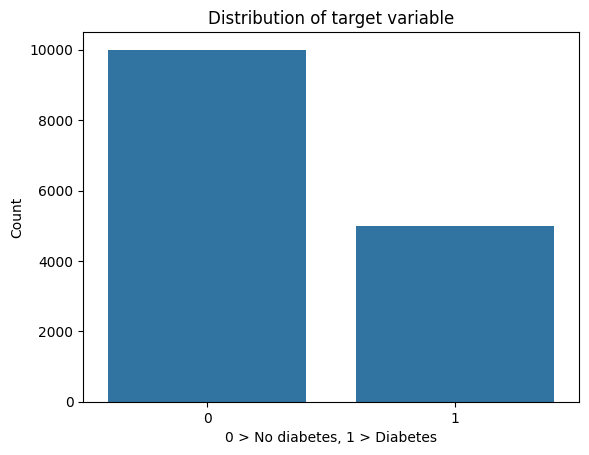

In [7]:
sns.countplot(x= 'Diabetic', data= diabetes)
plt.xlabel("0 > No diabetes, 1 > Diabetes")
plt.ylabel("Count")
plt.title("Distribution of target variable")
plt.show()

In [8]:
diabetes['Diabetic'].value_counts("%")*100

Diabetic
0    66.666667
1    33.333333
Name: proportion, dtype: float64

In [9]:
diabetes.groupby('Diabetic').describe()

PatientID                                                      \
             count          mean            std        min         25%   
Diabetic                                                                 
0          10000.0  1.505477e+06  288505.318777  1000038.0  1255712.25   
1           5000.0  1.497811e+06  290705.456782  1000326.0  1245424.75   

                                           Pregnancies          ...  \
                50%         75%        max       count    mean  ...   
Diabetic                                                        ...   
0         1512402.5  1754929.25  1999997.0     10000.0  2.2479  ...   
1         1494162.5  1755907.00  1999836.0      5000.0  5.1778  ...   

         DiabetesPedigree                Age                                  \
                      75%       max    count     mean        std   min   25%   
Diabetic                                                                       
0                0.521379  2.215815  10000.0  27.2090   9.928463  21.0  22.0   
1                0.774823  2.301594   5000.0  35.9952  13.780332  21.0  22.0   

                            
           50%   75%   max  
Diabetic                    
0         24.0  26.0  77.0  
1         37.0  46.0  67.0  

[2 rows x 72 columns]

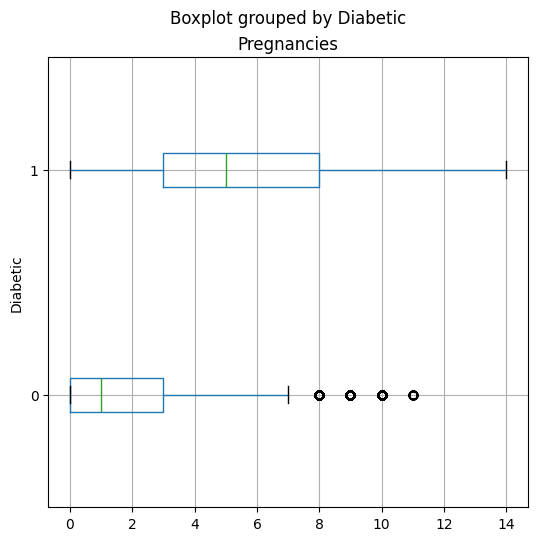

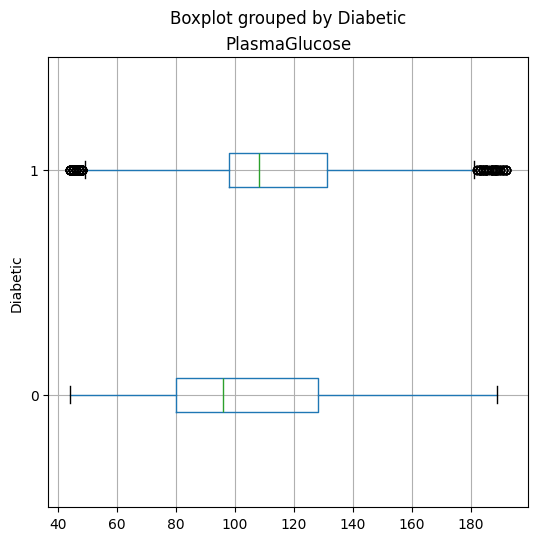

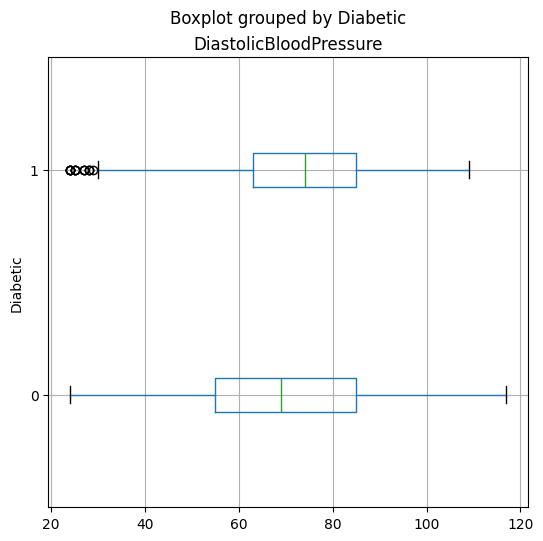

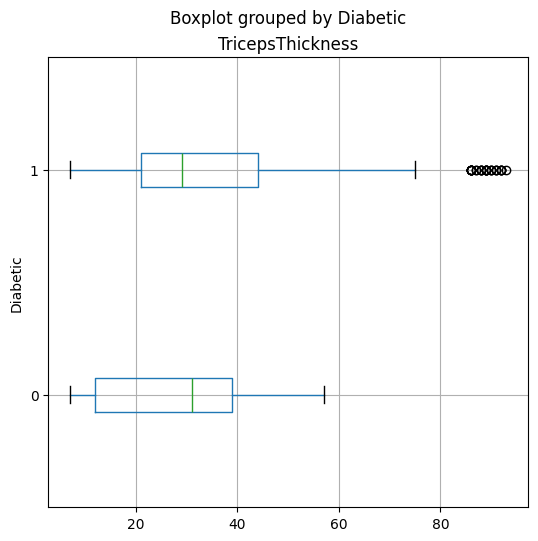

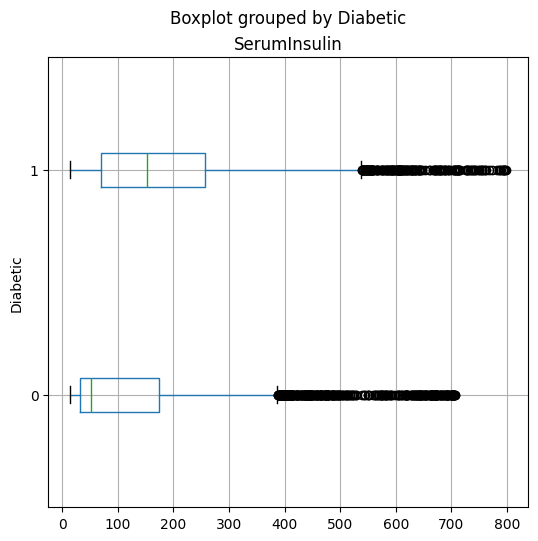

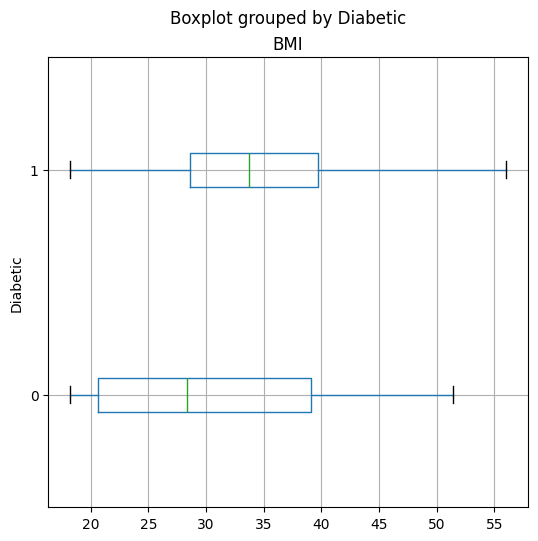

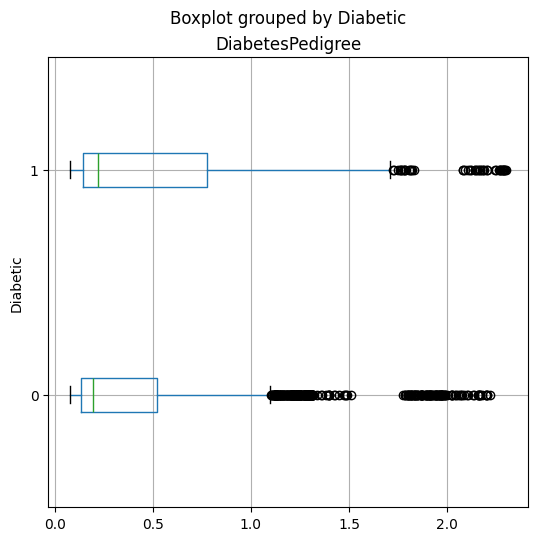

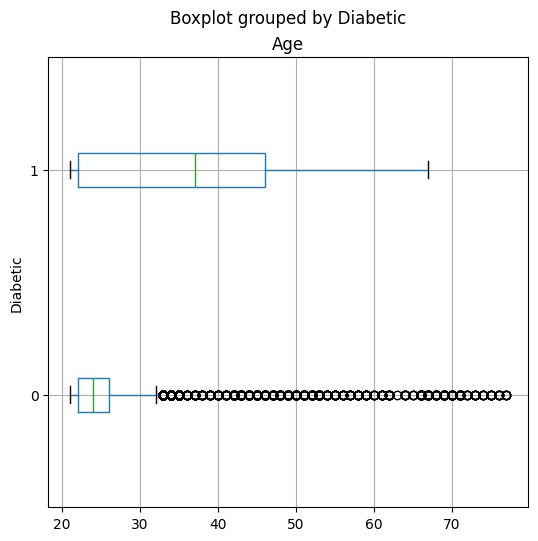

In [10]:
from matplotlib import pyplot as plt
%matplotlib inline

for col in features:
    diabetes.boxplot(column= col, by = 'Diabetic', figsize = (6,6), vert = False)
    plt.title(col)
    plt.show()

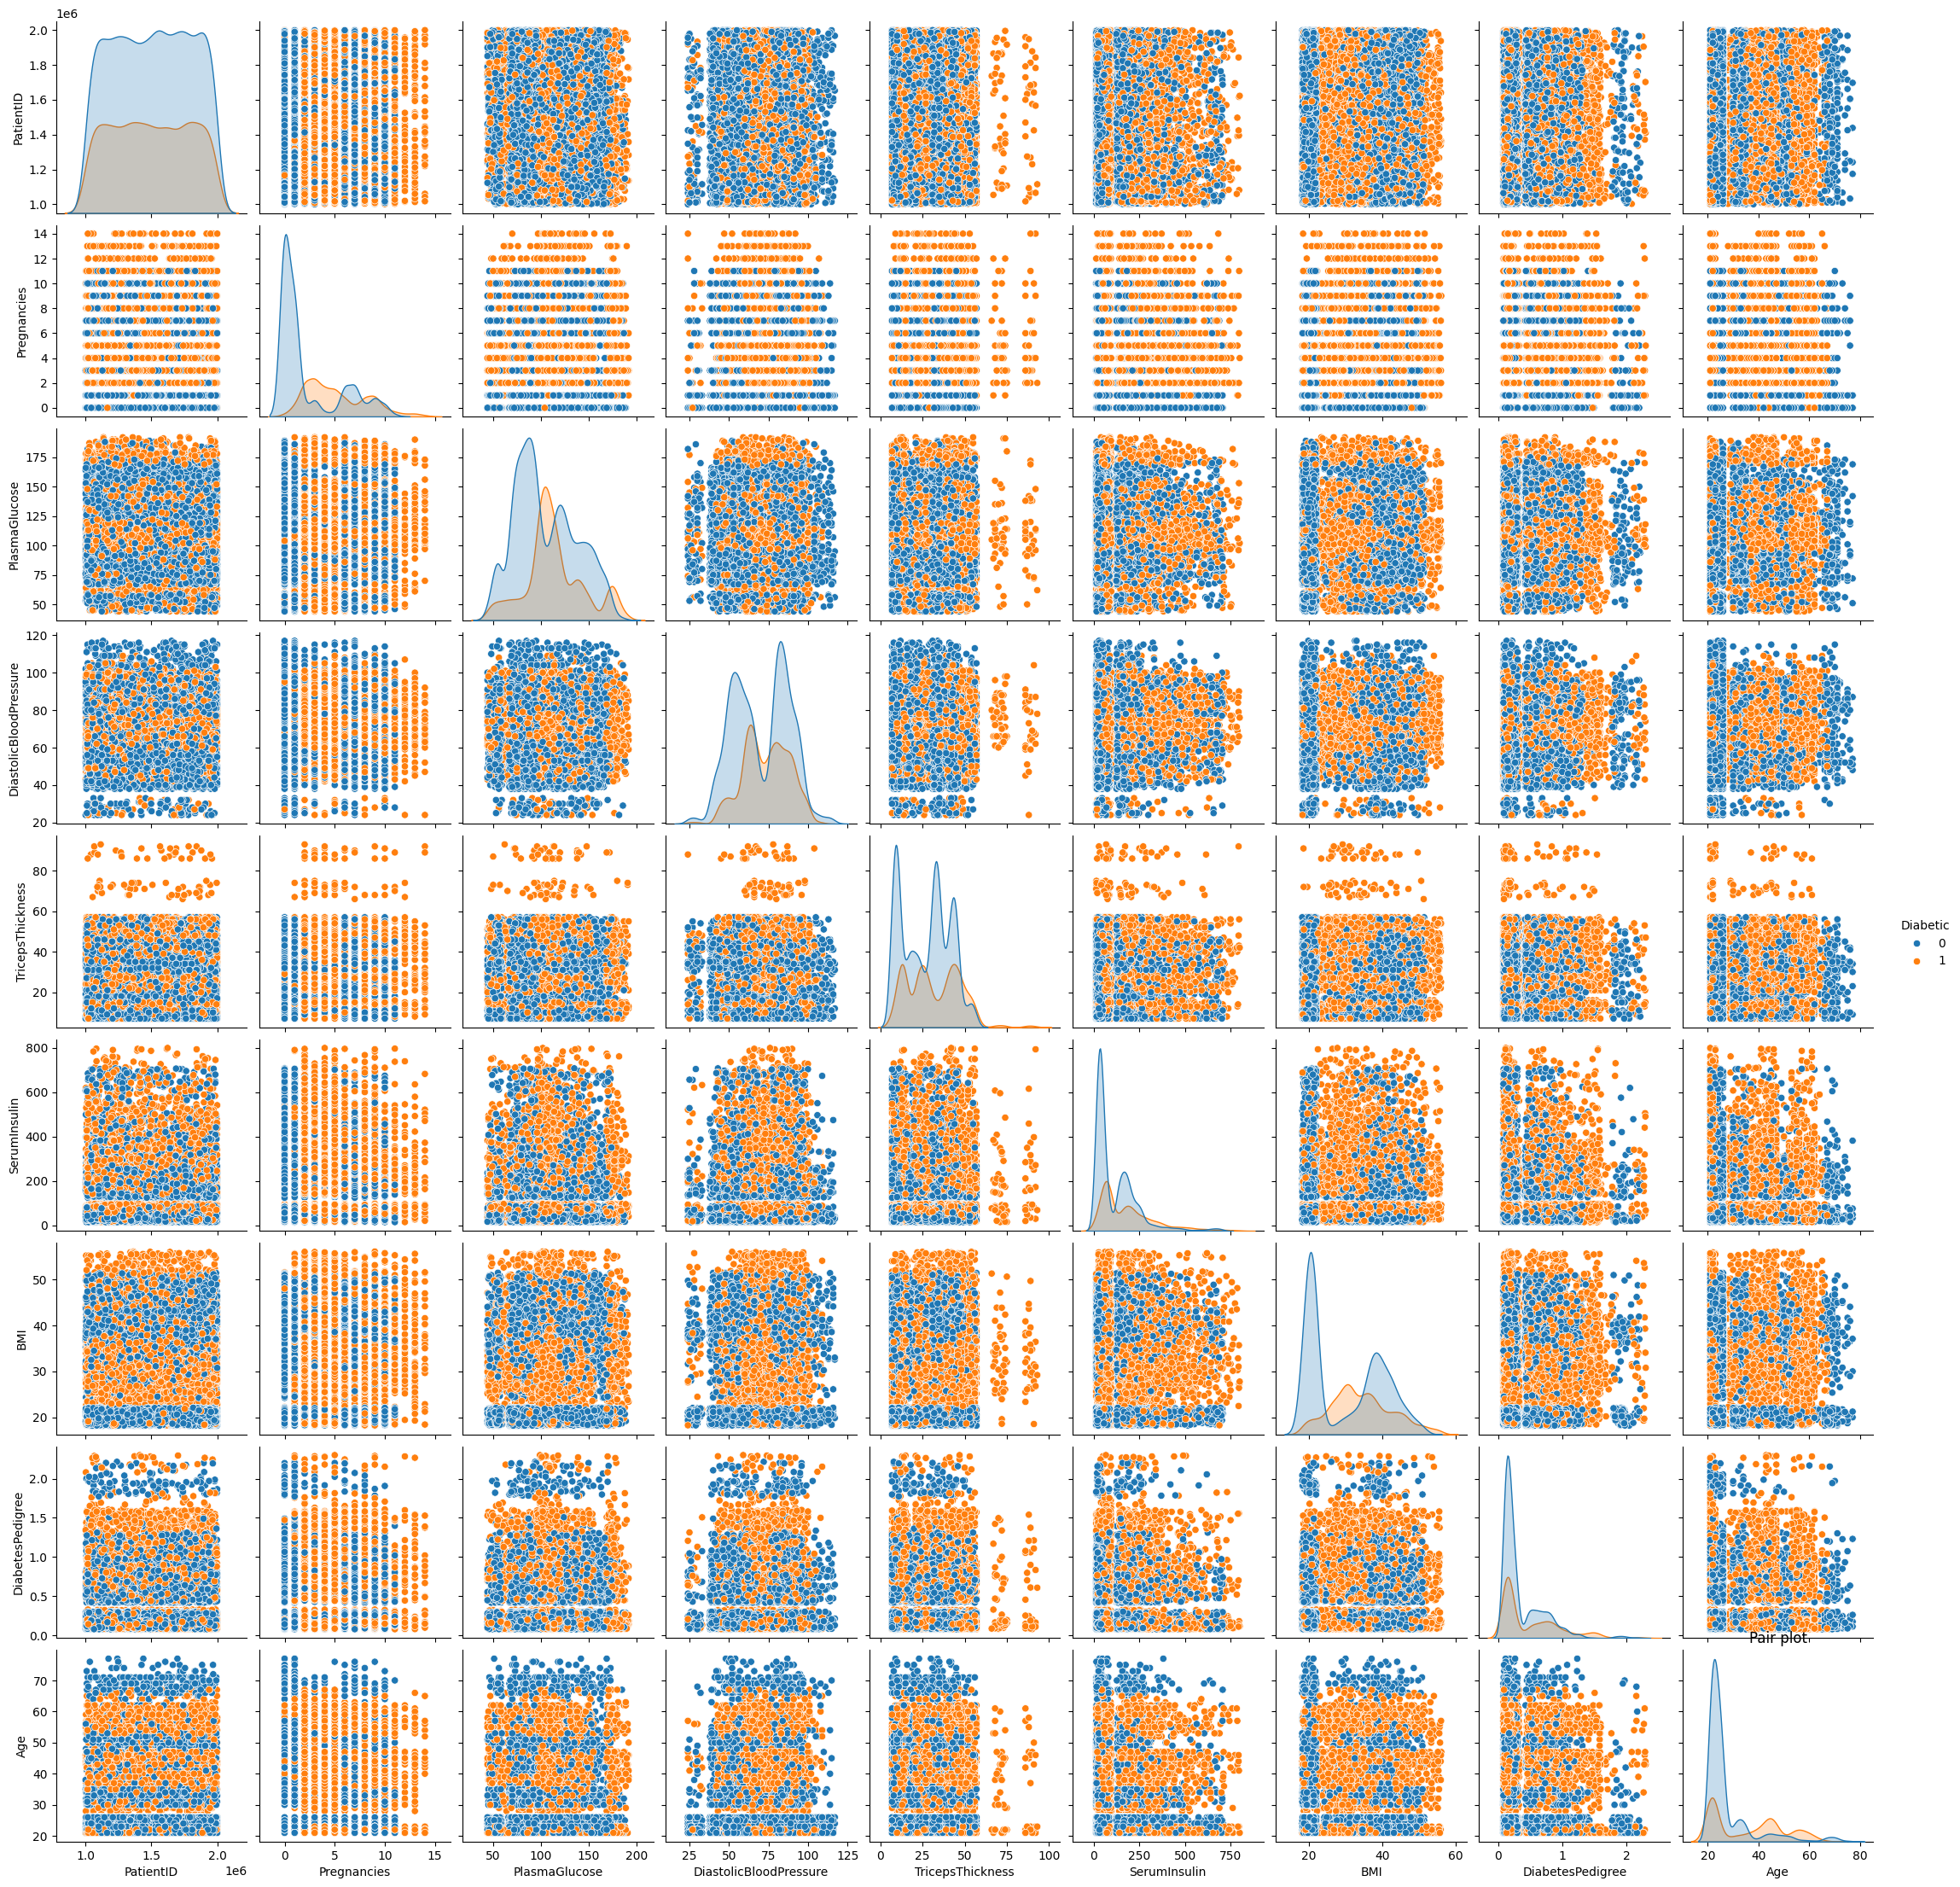

In [11]:
sns.pairplot(diabetes, hue = 'Diabetic')
plt.title("Pair plot")
plt.show()

In [12]:
diabetes.isnull().sum()

PatientID                 0
Pregnancies               0
PlasmaGlucose             0
DiastolicBloodPressure    0
TricepsThickness          0
SerumInsulin              0
BMI                       0
DiabetesPedigree          0
Age                       0
Diabetic                  0
dtype: int64

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, stratify= y, random_state= 17)
print(X_train.shape[0])
print(X_test.shape[0])

10500
4500


In [14]:
X_train['Age'].value_counts("%")*100

Age
21    16.838095
22    16.428571
23    13.542857
26     6.809524
25     6.561905
24     6.447619
45     2.171429
44     1.885714
43     1.752381
47     1.742857
46     1.733333
32     1.580952
35     1.504762
34     1.476190
30     1.466667
33     1.371429
31     1.333333
53     0.942857
42     0.819048
56     0.809524
55     0.790476
54     0.742857
38     0.723810
57     0.723810
41     0.704762
40     0.676190
39     0.676190
60     0.580952
59     0.552381
37     0.542857
61     0.514286
36     0.457143
52     0.428571
58     0.428571
62     0.400000
67     0.371429
50     0.361905
48     0.342857
29     0.333333
51     0.323810
49     0.304762
66     0.247619
69     0.247619
28     0.228571
71     0.228571
68     0.200000
70     0.171429
65     0.123810
64     0.085714
63     0.066667
73     0.047619
74     0.038095
72     0.028571
77     0.028571
76     0.028571
75     0.028571
Name: proportion, dtype: float64

In [15]:
X_test['Age'].value_counts("%")*100

Age
21    17.511111
22    16.911111
23    12.622222
25     6.711111
24     6.422222
26     6.355556
46     1.955556
45     1.933333
43     1.822222
34     1.800000
47     1.688889
44     1.644444
35     1.644444
32     1.333333
30     1.266667
31     1.244444
33     1.177778
42     1.066667
53     1.000000
55     1.000000
38     0.955556
56     0.822222
40     0.777778
54     0.755556
57     0.666667
39     0.666667
41     0.622222
58     0.577778
61     0.533333
49     0.511111
62     0.466667
50     0.444444
36     0.422222
60     0.422222
52     0.400000
71     0.400000
37     0.377778
59     0.377778
51     0.355556
29     0.333333
66     0.311111
69     0.288889
48     0.244444
70     0.244444
67     0.222222
68     0.133333
28     0.111111
65     0.111111
75     0.088889
73     0.044444
76     0.044444
64     0.044444
63     0.044444
72     0.022222
74     0.022222
77     0.022222
Name: proportion, dtype: float64

In [16]:
import numpy as np
unique_elements_train, counts_elements_train = np.unique(y_train, return_counts=True)
percentages_train = (counts_elements_train/y_train.size)*100

In [17]:
print(unique_elements_train)
print(counts_elements_train)
print(percentages_train)
print(y_train.shape)

[0 1]
[7000 3500]
[66.66666667 33.33333333]
(10500, 1)


In [18]:
unique_elements_test, counts_elements_test = np.unique(y_test, return_counts=True)
percentages_test = (counts_elements_test/y_test.size)*100

In [19]:
print(unique_elements_test)
print(counts_elements_test)
print(percentages_test)
print(y_test.shape)

[0 1]
[3000 1500]
[66.66666667 33.33333333]
(4500, 1)


In [20]:
from sklearn.linear_model import LogisticRegression

In [21]:
model = LogisticRegression()
model.fit(X_train, y_train)

c:\Users\LEON SUAREZ\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\LEON SUAREZ\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [22]:
predictions = model.predict(X_test)
print(predictions)

[0 0 0 ... 1 1 1]


In [23]:
print(y_test.values)

[[0]
 [0]
 [1]
 ...
 [0]
 [1]
 [1]]


In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predictions)
print(cm)

[[2626  374]
 [ 635  865]]


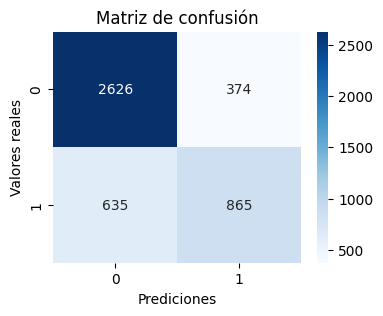

In [25]:
plt.figure(figsize=(4,3))
sns.heatmap(cm, annot= True, fmt= 'g', cmap= 'Blues')
plt.title("Matriz de confusión")
plt.xlabel("Prediciones")
plt.ylabel("Valores reales")
plt.show()

In [26]:
from sklearn.metrics import accuracy_score, classification_report
print("Accuracy:", accuracy_score(y_test, predictions))
print(classification_report(y_test, predictions))

Accuracy: 0.7757777777777778
              precision    recall  f1-score   support

           0       0.81      0.88      0.84      3000
           1       0.70      0.58      0.63      1500

    accuracy                           0.78      4500
   macro avg       0.75      0.73      0.74      4500
weighted avg       0.77      0.78      0.77      4500



In [27]:
print(classification_report(y_test,predictions,target_names=["No diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No diabetes       0.81      0.88      0.84      3000
    Diabetes       0.70      0.58      0.63      1500

    accuracy                           0.78      4500
   macro avg       0.75      0.73      0.74      4500
weighted avg       0.77      0.78      0.77      4500



In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score

print("Overall precision:" , precision_score(y_test, predictions, average= None))
print("Overall recall:", recall_score(y_test, predictions, average= None))
print("Overall F1:", f1_score(y_test, predictions, average= None))

Overall precision: [0.80527446 0.69814366]
Overall recall: [0.87533333 0.57666667]
Overall F1: [0.83884364 0.63161738]


In [29]:
y_scores = model.predict_proba(X_test)
pd.DataFrame({'Proba_0': y_scores[:,0],'Proba_1':y_scores[:,1], 'categoria': predictions}).head(15)

,Proba_0,Proba_1,categoria
0,0.920739,0.079261,0
1,0.968917,0.031083,0
2,0.824908,0.175092,0
3,0.673280,0.326720,0
4,0.604793,0.395207,0
5,0.979051,0.020949,0
6,0.143138,0.856862,1
7,0.602951,0.397049,0
8,0.860302,0.139698,0
9,0.968764,0.031236,0


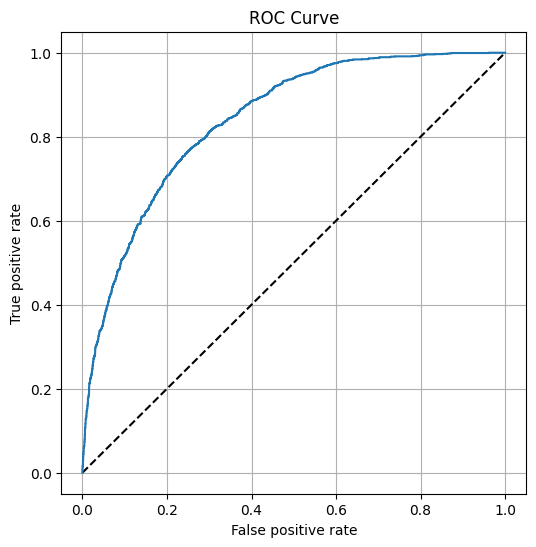

In [30]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_scores[:,1])
fig = plt.figure(figsize=(6,6))
plt.plot([0,1],[0,1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC Curve')
plt.grid()
plt.show()

In [31]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_scores[:,1])
print(auc)

0.8408768888888888


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [33]:
numeric_features = [0,1,2,3,4,5,6]
numeric_transformer = Pipeline(steps=[('Scaler', StandardScaler())])

categorical_features = [7]
categorical_transformer = Pipeline(steps=[('OneHot', OneHotEncoder(handle_unknown='ignore'))])

In [34]:
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features),('cat', categorical_transformer, categorical_features)])

In [35]:
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('logregressor', LogisticRegression())])
model = pipeline.fit(X_train, y_train)
print(model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('Scaler',
                                                                   StandardScaler())]),
                                                  [0, 1, 2, 3, 4, 5, 6]),
                                                 ('cat',
                                                  Pipeline(steps=[('OneHot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [7])])),
                ('logregressor', LogisticRegression())])


c:\Users\LEON SUAREZ\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [36]:
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('logregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','PlasmaGlucose','DiastolicBloodPressure',...,'BMI', 'DiabetesPedigree','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remai

In [37]:
predictions = model.predict(X_test)
y_scores = model.predict_proba(X_test)

cm = confusion_matrix(y_test, predictions)

In [38]:
cm

array([[2681,  319],
       [ 411, 1089]])

In [39]:
accuracy_score(y_test, predictions)

0.8377777777777777

In [40]:
precision_score(y_test, predictions)

0.7734375

In [41]:
recall_score(y_test, predictions)

0.726

In [42]:
f1_score(y_test, predictions)

0.7489683631361761

In [43]:
auc = roc_auc_score(y_test, y_scores[:,1])
print(str(auc))

0.9187544444444444


In [44]:
fpr, tpr, thresholds = roc_curve(y_test, y_scores[:,1])

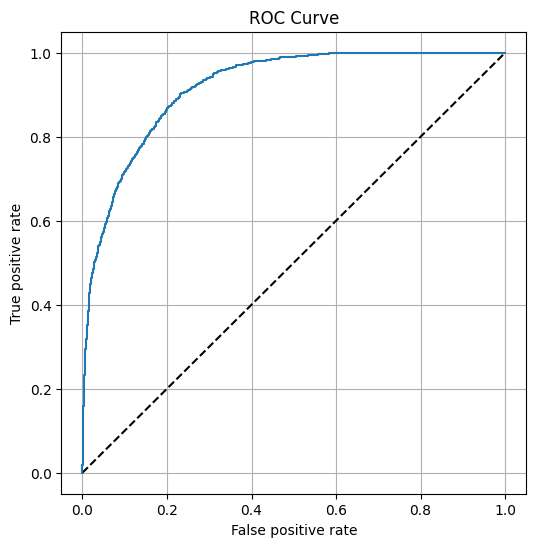

In [45]:
fig = plt.figure(figsize=(6,6))
plt.plot([0,1],[0,1], 'k--')
plt.plot(fpr, tpr)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC Curve')
plt.grid()
plt.show()

In [46]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [47]:
model_tree = DecisionTreeClassifier(random_state= 42)

model_tree.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy_tree = accuracy_score(y_test, y_pred)
print(accuracy_tree)

0.8377777777777777


In [48]:
print(y_pred)

[0 0 1 ... 0 1 1]


In [49]:
print(y_test.values)

[[0]
 [0]
 [1]
 ...
 [0]
 [1]
 [1]]


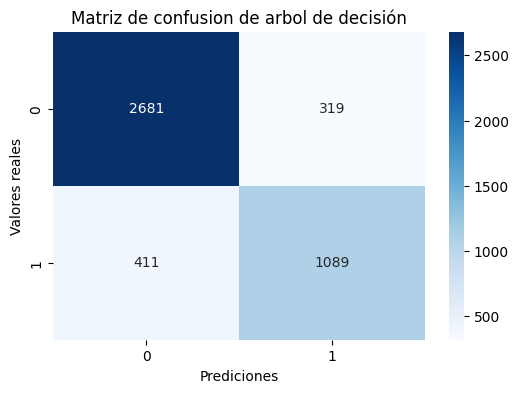

In [50]:
cm_t = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm_t, annot= True, fmt = 'g', cmap = 'Blues')
plt.title("Matriz de confusion de arbol de decisión")
plt.xlabel("Prediciones")
plt.ylabel("Valores reales")
plt.show()

In [51]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.89      0.88      3000
           1       0.77      0.73      0.75      1500

    accuracy                           0.84      4500
   macro avg       0.82      0.81      0.81      4500
weighted avg       0.84      0.84      0.84      4500



[[2681  319]
 [ 411 1089]]
0.8986666666666666
0.84251968503937
0.856
0.8492063492063492
0.888


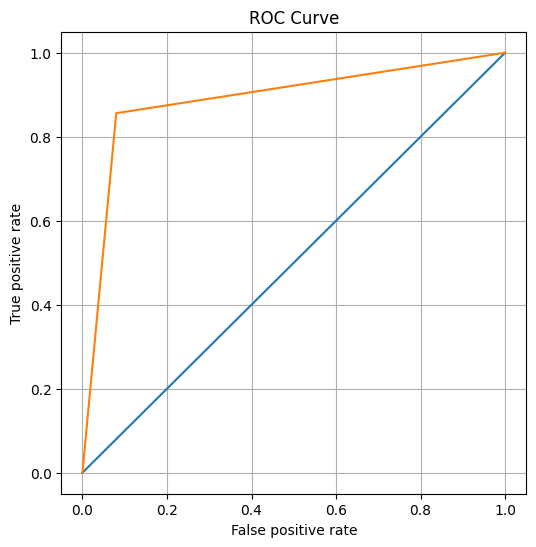

In [52]:
predictions = model_tree.predict(X_test)
y_scores = model_tree.predict_proba(X_test)

cm_t = confusion_matrix(y_test, predictions)
print(cm)
print(accuracy_score(y_test, predictions))
print(precision_score(y_test, predictions))
print(recall_score(y_test, predictions))
print(f1_score(y_test, predictions))
auc = roc_auc_score(y_test, y_scores[:,1])
print(str(auc))

fpr, tpr, thresholds = roc_curve(y_test, y_scores[:,1])

fig = plt.figure(figsize = (6,6))
plt.plot([0,1],[0,1])
plt.plot(fpr, tpr)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curve")
plt.grid()
plt.show()

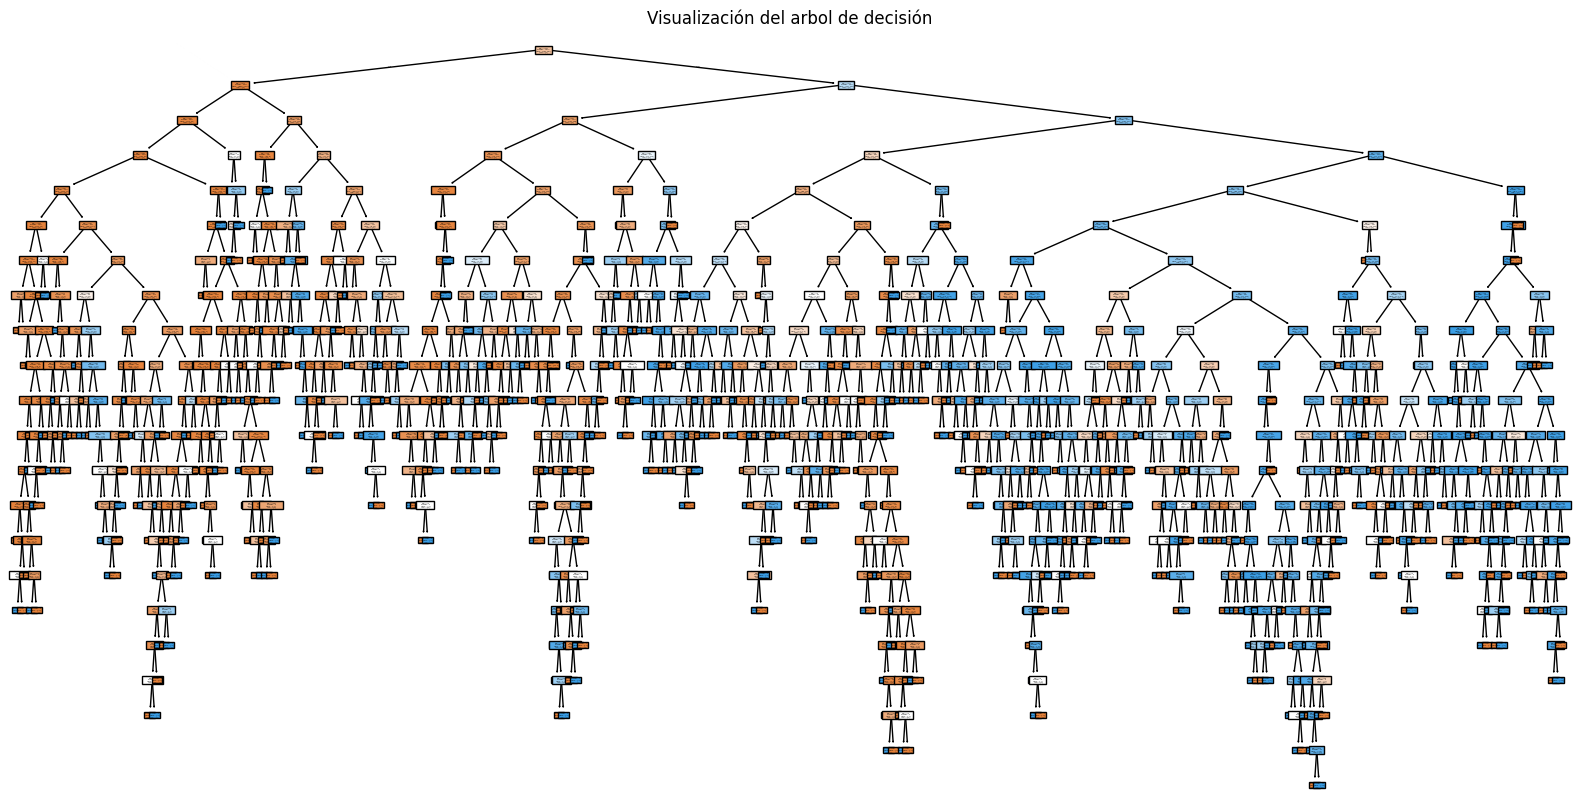

In [57]:
plt.figure(figsize = (20,10))
plot_tree(model_tree,filled=True,feature_names=X_train.columns,class_names=True)
plt.title("Visualización del arbol de decisión")
plt.show()

In [58]:
model_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
model_tree.fit(X_train, y_train)
y_pred = model_tree.predict(X_test)
print(accuracy_score(y_test,y_pred))

0.8471111111111111


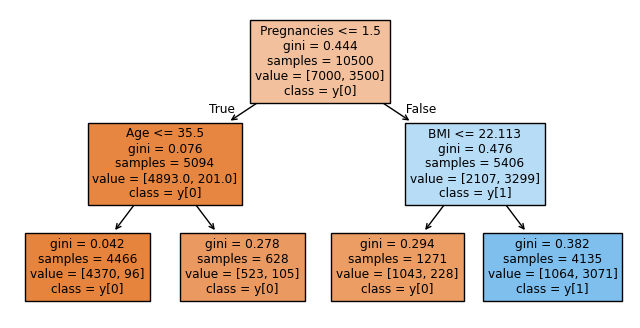

In [59]:
plt.figure(figsize=(8,4))
plot_tree(model_tree, filled=True, feature_names=X_train.columns, class_names=True)
plt.show()

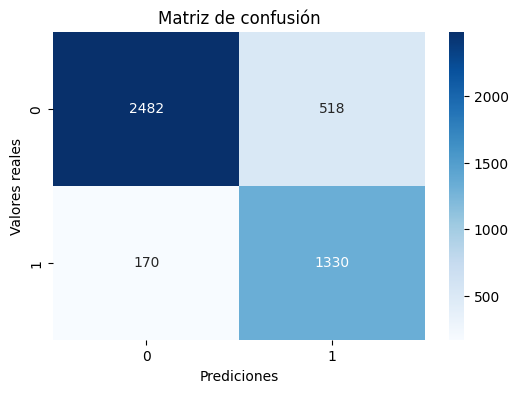

In [60]:
cm_t = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm_t, annot = True, fmt = 'g', cmap = 'Blues')
plt.title('Matriz de confusión')
plt.xlabel("Prediciones")
plt.ylabel("Valores reales")
plt.show()

In [61]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.94      0.83      0.88      3000
           1       0.72      0.89      0.79      1500

    accuracy                           0.85      4500
   macro avg       0.83      0.86      0.84      4500
weighted avg       0.86      0.85      0.85      4500



In [63]:
model_tree = DecisionTreeClassifier(max_depth=4,random_state=42, criterion='entropy')
model_tree.fit(X_train, y_train)
y_pred=model_tree.predict(X_test)

print(accuracy_score(y_test, y_pred))

0.8835555555555555


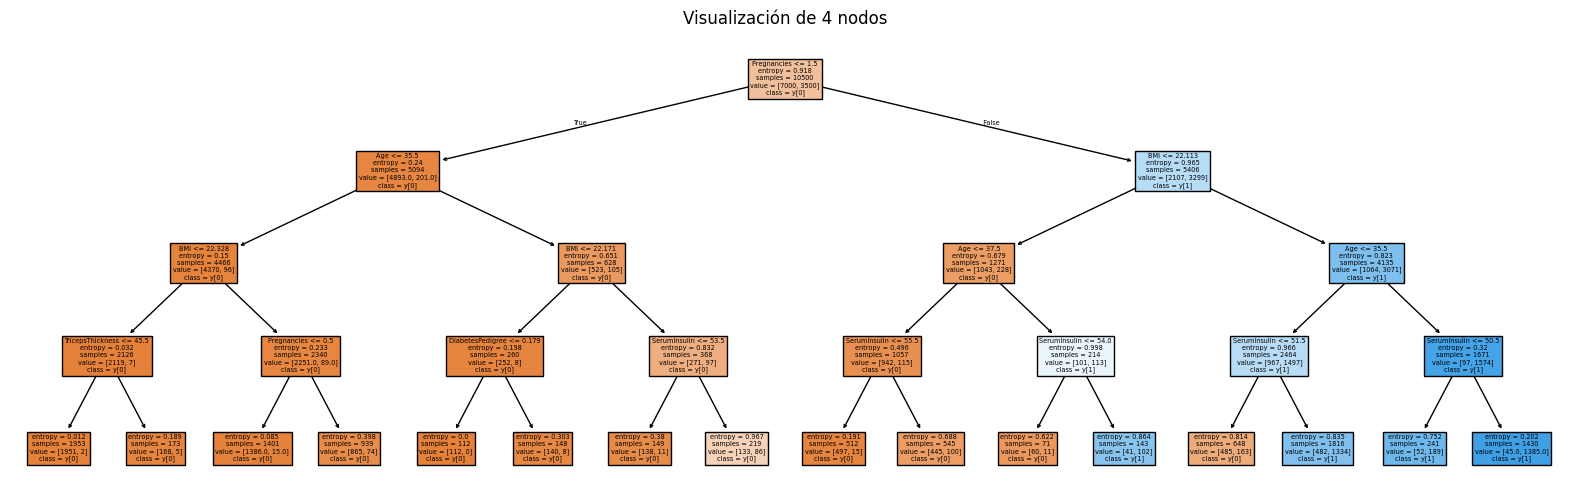

In [68]:
plt.figure(figsize=(20,6))
plot_tree(model_tree, filled=True, feature_names=X_train.columns, class_names=True)
plt.title("Visualización de 4 nodos")
plt.show()

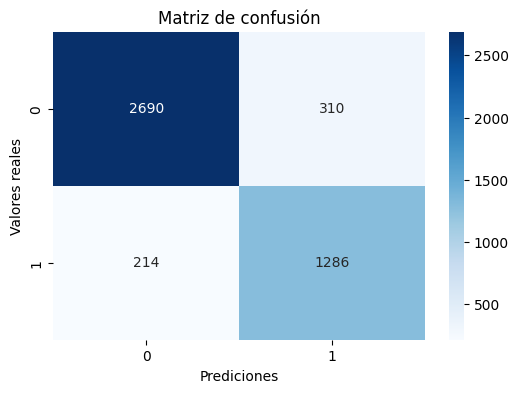

In [ ]:
cm_t = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm_t, annot = True, fmt = 'g', cmap = 'Blues')
plt.title('Matriz de confusión')
plt.xlabel("Prediciones")
plt.ylabel("Valores reales")
plt.show()

In [69]:
model_tree = DecisionTreeClassifier(max_depth=4,criterion='gini', random_state=42, splitter= 'random')
model_tree.fit(X_train, y_train)
y_pred=model_tree.predict(X_test)

print(accuracy_score(y_test, y_pred))


0.7224444444444444


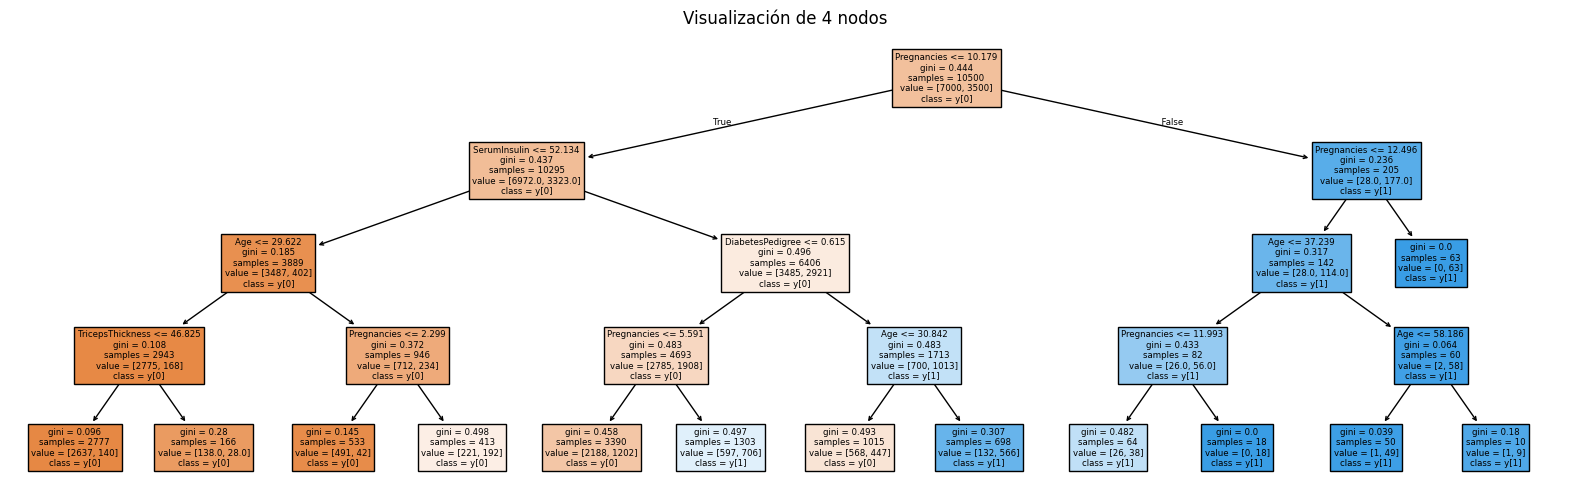

In [70]:
plt.figure(figsize=(20,6))
plot_tree(model_tree, filled=True, feature_names=X_train.columns, class_names=True)
plt.title("Visualización de 4 nodos")
plt.show()

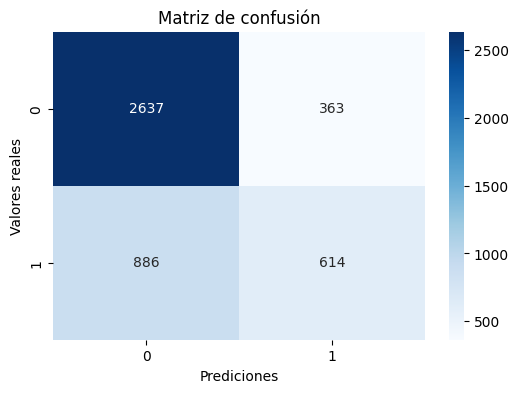

In [71]:
cm_t = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm_t, annot = True, fmt = 'g', cmap = 'Blues')
plt.title('Matriz de confusión')
plt.xlabel("Prediciones")
plt.ylabel("Valores reales")
plt.show()

In [73]:
numeric_features = [0,1,2,3,4,5,6]
numeric_transformer = Pipeline(steps=[('Scaler', StandardScaler())])

categorical_features = [7]
categorical_transformer = Pipeline(steps=[('OneHot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features),('cat', categorical_transformer, categorical_features)])

pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('DecisionTreeClassifier', DecisionTreeClassifier())])
model = pipeline.fit(X_train, y_train)
print(model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('Scaler',
                                                                   StandardScaler())]),
                                                  [0, 1, 2, 3, 4, 5, 6]),
                                                 ('cat',
                                                  Pipeline(steps=[('OneHot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [7])])),
                ('DecisionTreeClassifier', DecisionTreeClassifier())])


In [75]:
model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('DecisionTreeClassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','PlasmaGlucose','DiastolicBloodPressure',...,'BMI', 'DiabetesPedigree','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyi

In [76]:
y_pred_pipeline = pipeline.predict(X_test)
acr= accuracy_score(y_test, y_pred_pipeline)
print(acr)

0.8884444444444445


In [78]:
from xgboost import XGBClassifier

modelo = XGBClassifier(random_state = 42)
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

print(accuracy_score(y_test, y_pred))

0.9524444444444444


In [79]:
print(y_test.values)

[[0]
 [0]
 [1]
 ...
 [0]
 [1]
 [1]]


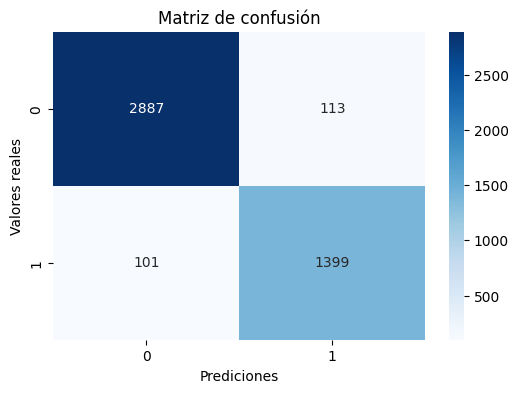

In [80]:
cm_t = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm_t, annot = True, fmt = 'g', cmap = 'Blues')
plt.title('Matriz de confusión')
plt.xlabel("Prediciones")
plt.ylabel("Valores reales")
plt.show()

In [81]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.97      0.96      0.96      3000
           1       0.93      0.93      0.93      1500

    accuracy                           0.95      4500
   macro avg       0.95      0.95      0.95      4500
weighted avg       0.95      0.95      0.95      4500



[[2887  113]
 [ 101 1399]]
0.9524444444444444
0.9252645502645502
0.9326666666666666
0.9289508632138114
0.9906360000000001


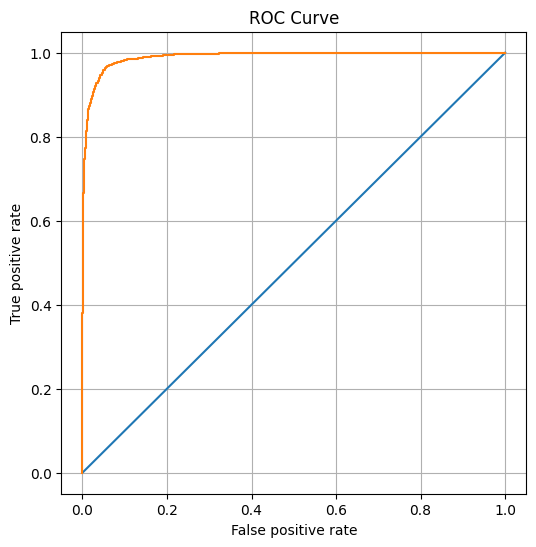

In [83]:
predictions = modelo.predict(X_test)
y_scores = modelo.predict_proba(X_test)

cm = confusion_matrix(y_test, predictions)
print(cm)
print(accuracy_score(y_test, predictions))
print(precision_score(y_test, predictions))
print(recall_score(y_test, predictions))
print(f1_score(y_test, predictions))
auc = roc_auc_score(y_test, y_scores[:,1])
print(str(auc))

fpr, tpr, thresholds = roc_curve(y_test, y_scores[:,1])

fig = plt.figure(figsize = (6,6))
plt.plot([0,1],[0,1])
plt.plot(fpr, tpr)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curve")
plt.grid()
plt.show()